# Ce que valent les pourcentages du projet

Tous les chapitres précédents annoncent des pourcentages : 40 intentions reconnues sur 40, 85,6 %
de rapprochements justes, 60 % de marchés attribués à une PME, 75,8 % de concordance de la
détection. Aucun ne disait **plus ou moins combien**.

Ce notebook répare cela, et pose au passage une question que le projet n'avait pas posée : quand
une règle est calée sur des données, puis appliquée à ces mêmes données, de combien la mesure
est-elle flattée ?

## Pourquoi cette étape, et pourquoi maintenant

| Option | Avantage | Limite | Ce qui a fait pencher |
|---|---|---|---|
| Ne rien faire, publier les points | rapide | un chiffre d'échantillon sans intervalle affirme plus que la mesure n'autorise | écarté |
| Ajouter un intervalle partout | rassurant | **faux là où le hasard du tirage n'est pas le problème** | écarté |
| Nommer la source d'incertitude de chaque chiffre, et ne calculer que là où elle se calcule | la seule honnête | demande de trier les mesures une par une | **retenu** |

La deuxième ligne est le piège de cette étape. Un intervalle de confiance ne mesure que le hasard
du tirage. Il ne dit rien d'un échantillon mal construit, d'une non-réponse, ni d'une étiquette
approximative. Mis au mauvais endroit, il donne un air de rigueur à une mesure dont le défaut est
ailleurs.

In [1]:
import csv
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt

sys.path.append("..")
from mesures.figures import ENCRE, FILET, GRIS, SERIE_1, soigner  # noqa: E402
from mesures.incertitude import clopper_pearson, wald, wilson  # noqa: E402

%matplotlib inline

RESULTATS = Path("../mesures/resultats")


def lire(nom):
    with (RESULTATS / f"{nom}.csv").open(encoding="utf-8") as fichier:
        return list(csv.DictReader(fichier))


# La base DuckDB est ouverte en lecture seule : ce notebook ne modifie rien.
con = duckdb.connect("../donnees/commande_publique.duckdb", read_only=True)
marches = con.execute("select count(*) from or_marches").fetchone()[0]
print(f"marchés en base : {marches:,}".replace(",", " "))

marchés en base : 1 999 474


## 1. Le cas qui tranche : quarante sur quarante

L'assistant reconnaît l'intention des 40 questions du jeu de test. Quarante sur quarante. La
question n'est pas de savoir si c'est bien, c'est de savoir ce que ce résultat autorise à dire sur
la **quarante et unième** question.

Trois formules répondent, et elles ne répondent pas la même chose.

In [2]:
cas = [
    ("intentions reconnues", 40, 40),
    ("citations justes", 448, 448),
    ("avis rapprochés", 107, 300),
]

print(f"{'mesure':<22} {'observé':>8}   {'Wald':>18}   {'Wilson':>18}   {'exact':>18}")
for nom, succes, essais in cas:
    observe = f"{100 * succes / essais:.1f} %"
    formats = []
    for formule in (wald, wilson, clopper_pearson):
        bas, haut = formule(succes, essais)
        formats.append(f"[{bas:>6.1f} ; {haut:>6.1f}]")
    print(f"{nom:<22} {observe:>8}   " + "   ".join(f"{f:>18}" for f in formats))

mesure                  observé                 Wald               Wilson                exact
intentions reconnues    100.0 %    [ 100.0 ;  100.0]    [  91.2 ;  100.0]    [  91.2 ;  100.0]
citations justes        100.0 %    [ 100.0 ;  100.0]    [  99.1 ;  100.0]    [  99.2 ;  100.0]
avis rapprochés          35.7 %    [  30.2 ;   41.1]    [  30.5 ;   41.2]    [  30.2 ;   41.4]


Sur la première ligne, la formule que tout le monde connaît, `p ± 1,96 racine(p(1-p)/n)`, annonce
**100 % sans aucune marge**. Traduit en français : la quarante et unième question sera reconnue,
c'est certain. Aucune mesure ne permet de dire cela.

La raison est arithmétique. Quand `p` vaut 1, le produit `p(1-p)` vaut zéro, et la marge aussi. La
formule suppose que la proportion observée est la vraie proportion ; à la frontière, cette
hypothèse s'effondre et elle ne le signale pas.

Wilson recentre la proportion observée vers 0,5 d'une quantité qui dépend de la taille de
l'échantillon. L'intervalle reste donc ouvert, et il donne ici un plancher autour de 91 %.

C'est la formule que le notebook 06 utilisait. Elle y était inoffensive parce que la proportion
mesurée valait 58,9 %, loin des bords. Elle ne l'est plus ici.

In [3]:
# La meme formule, sur une proportion faible : elle sort de l'intervalle des valeurs possibles.
bas, haut = wald(1, 100)
print(f"1 succès sur 100, formule naïve : [{bas:.1f} ; {haut:.1f}]")
print(f"1 succès sur 100, Wilson        : [{wilson(1, 100)[0]:.1f} ; {wilson(1, 100)[1]:.1f}]")
print()
print("Une borne basse négative n'est pas une approximation grossière, c'est une impossibilité :")
print("aucune proportion ne peut être inférieure à zéro.")

1 succès sur 100, formule naïve : [-1.0 ; 3.0]
1 succès sur 100, Wilson        : [0.2 ; 5.4]

Une borne basse négative n'est pas une approximation grossière, c'est une impossibilité :
aucune proportion ne peut être inférieure à zéro.


## 2. La justesse du rapprochement : un bootstrap, et pourquoi pas une formule

La justesse du rapprochement BOAMP vers DECP ne se lit pas directement. Elle vient de 60 paires
relues à la main, douze par tranche de similarité, puis **redressées** par l'effectif réel
de chaque tranche : l'échantillon compte douze paires par tranche, alors que les tranches n'ont pas
du tout le même poids dans la réalité.

Un estimateur pondéré de ce genre n'a pas de formule de variance simple, d'autant que les paires
marquées « doute » sont retirées du dénominateur, lequel varie donc d'un tirage à l'autre. On
rééchantillonne : on tire des paires à l'intérieur de chaque tranche, on recalcule la justesse
redressée, et on recommence des milliers de fois.

In [4]:
justesse = lire("incertitude-justesse-rapprochement")

print("seuil   relues   justesse   bootstrap 95 %        largeur   dégénéré")
for ligne in justesse:
    intervalle = f"[{ligne['bootstrap_bas']:>5} ; {ligne['bootstrap_haut']:>5}]"
    print(
        f"{ligne['seuil_objet']:>5}   {ligne['paires_relues']:>6}   "
        f"{ligne['justesse_pourcent']:>7} %   {intervalle:>18}   "
        f"{ligne['largeur_points']:>5} pts   {ligne['bootstrap_degenere']}"
    )

seuil   relues   justesse   bootstrap 95 %        largeur   dégénéré
  0.4       60      66.0 %      [ 59.3 ;  72.3]    13.0 pts   non
  0.5       48      85.6 %      [ 76.7 ;  94.0]    17.3 pts   non
  0.6       36      94.1 %      [ 88.4 ;  98.7]    10.2 pts   non
  0.7       24      97.8 %      [ 92.7 ; 100.0]     7.3 pts   non
  0.8       12     100.0 %      [100.0 ; 100.0]     0.0 pts   oui


Le seuil retenu par le projet est 0,5. Sa justesse annoncée était **85,6 %**. L'intervalle couvre
de 76,7 à 94,0, soit **plus de dix-sept points**. La décision reste la bonne, puisque l'intervalle
du seuil 0,5 ne chevauche pas celui du seuil 0,4, mais la précision du chiffre était illusoire.

Avec 60 paires relues, on ne pouvait pas obtenir mieux. C'est le prix du seul travail du projet qui
ne s'automatise pas.

### Combien de tirages faut-il ?

Le module en fait 10 000. Ce nombre mérite d'être justifié plutôt que choisi par habitude : trop
peu, et les bornes bougent d'une exécution à l'autre ; trop, et on attend sans rien gagner.

**À MODIFIER pour voir :** changer la liste `nombres_de_tirages` ci-dessous.

In [5]:
import random

from mesures.incertitude import (
    effectifs_par_tranche,
    justesse_par_tranche,
    justesse_ponderee,
)

verdicts = list(
    csv.DictReader(
        sorted(Path("../mesures/verification").glob("*-verdicts-rapprochement.csv"))[-1].open(
            encoding="utf-8"
        )
    )
)
groupes = justesse_par_tranche(verdicts)
effectifs = effectifs_par_tranche()

nombres_de_tirages = [100, 1_000, 10_000, 50_000]
SEUIL_OBSERVE = 0.5

print(f"seuil {SEUIL_OBSERVE}, deux exécutions indépendantes par nombre de tirages")
print("tirages    exécution 1          exécution 2          écart des bornes")
for nombre in nombres_de_tirages:
    bornes = []
    for graine in (1, 2):
        # Graine fixee : on veut comparer deux suites reproductibles, pas du hasard
        # cryptographique.
        alea = random.Random(graine)  # noqa: S311
        simulations = []
        for _ in range(nombre):
            tires = {nom: [alea.choice(v) for _ in v] if v else [] for nom, v in groupes.items()}
            valeur = justesse_ponderee(tires, effectifs, SEUIL_OBSERVE)
            if valeur is not None:
                simulations.append(100 * valeur)
        simulations.sort()
        bornes.append(
            (
                simulations[int(0.025 * len(simulations))],
                simulations[min(len(simulations) - 1, int(0.975 * len(simulations)))],
            )
        )
    ecart = max(abs(bornes[0][0] - bornes[1][0]), abs(bornes[0][1] - bornes[1][1]))
    print(
        f"{nombre:>7}    [{bornes[0][0]:5.1f} ; {bornes[0][1]:5.1f}]    "
        f"[{bornes[1][0]:5.1f} ; {bornes[1][1]:5.1f}]    {ecart:>5.1f} point(s)"
    )

seuil 0.5, deux exécutions indépendantes par nombre de tirages
tirages    exécution 1          exécution 2          écart des bornes
    100    [ 76.1 ;  95.1]    [ 76.8 ;  96.4]      1.3 point(s)
   1000    [ 76.5 ;  93.9]    [ 76.4 ;  94.2]      0.3 point(s)


  10000    [ 76.8 ;  93.8]    [ 76.7 ;  94.0]      0.2 point(s)


  50000    [ 76.8 ;  93.9]    [ 76.7 ;  93.9]      0.1 point(s)


À 100 tirages, deux exécutions s'écartent de plus d'un point : l'intervalle publié dépendrait du
hasard du calcul autant que de celui des données. Dès 1 000 tirages l'écart tombe à trois dixièmes
de point, et 10 000 n'en gagne qu'un ou deux de plus.

Autrement dit, **1 000 aurait suffi**. Les 10 000 du module sont une marge, pas une nécessité, et
elle coûte moins d'une seconde. Ce qui compte vraiment est ailleurs : sans graine fixe, la figure
du mémoire changerait à chaque exécution alors qu'aucune donnée n'aurait bougé.

## 3. Là où le bootstrap ne sait rien dire

Au seuil le plus haut, les douze paires relues sont toutes justes. Le rééchantillonnage ne peut
tirer que des valeurs déjà présentes dans l'échantillon : s'il n'y en a qu'une, il la répète. Les
10 000 simulations donnent toutes exactement 100 %, et l'intervalle se referme sur un point.

**Un intervalle de largeur nulle se lit comme une certitude. Ici, il signale l'inverse.** Le cas est
détecté et marqué dans le CSV, et l'intervalle exact, qui ne dépend pas du rééchantillonnage, prend
le relais.

In [6]:
degenere = [ligne for ligne in justesse if ligne["bootstrap_degenere"] == "oui"]
for ligne in degenere:
    print(
        f"seuil {ligne['seuil_objet']} : {ligne['paires_justes']} paires justes sur "
        f"{ligne['paires_relues']} relues"
    )
    print(
        f"  bootstrap : [{ligne['bootstrap_bas']} ; {ligne['bootstrap_haut']}]  "
        "<- largeur nulle, la méthode n'a plus de prise"
    )
    print(
        f"  exact     : [{ligne['exact_sans_redressement_bas']} ; "
        f"{ligne['exact_sans_redressement_haut']}]  <- ce qu'on peut honnêtement dire"
    )

seuil 0.8 : 12 paires justes sur 12 relues
  bootstrap : [100.0 ; 100.0]  <- largeur nulle, la méthode n'a plus de prise
  exact     : [73.5 ; 100.0]  <- ce qu'on peut honnêtement dire


## 4. L'incertitude qui ne vient pas du tirage

Le notebook 06 estimait la part attribuée à une PME sur un échantillon de 170 titulaires
interrogés par l'API, et l'annonçait avec une marge de tirage. Depuis, l'enrichissement a été
appliqué à toute la table : la part n'est plus estimée, elle est **comptée**.

On pourrait croire que l'incertitude a disparu. Elle a changé de nature.

In [7]:
pme = lire("incertitude-recensement-pme")[0]

# L'unite de comptage est l'attribution, soit un couple marche-titulaire : un groupement
# d'entreprises en produit plusieurs pour un seul marche. Le preciser avant d'annoncer le
# pourcentage, parce que c'est l'erreur la plus facile a commettre sur ce jeu.
print(f"attributions                : {int(pme['attributions']):,}".replace(",", " "))
print(f"marchés distincts           : {int(pme['marches']):,}".replace(",", " "))
print(f"titulaire résolu            : {int(pme['resolus']):,}".replace(",", " "))
print(
    f"titulaire non résolu        : {int(pme['non_resolus']):,}"
    f" ({pme['part_non_resolus_pourcent']} %)".replace(",", " ")
)
print()
print(f"part de PME sur les résolus : {pme['part_pme_sur_resolus_pourcent']} % des attributions")
print(
    f"à l'échelle du marché       : "
    f"{pme['part_marches_avec_au_moins_une_pme_pourcent']} % ont au moins une PME"
)
print(f"si aucun non-résolu n'est une PME : {pme['borne_basse_pourcent']} %")
print(f"si tous le sont                   : {pme['borne_haute_pourcent']} %")
print()
print(f"étendue de non-réponse            : {pme['etendue_non_reponse_points']} points")
print(f"hasard de tirage de l'échantillon : {pme['largeur_tirage_echantillon_points']} points")

attributions                : 1 999 474
marchés distincts           : 1 738 289
titulaire résolu            : 1 864 153
titulaire non résolu        : 135 321 (6.8 %)

part de PME sur les résolus : 60.8 % des attributions
à l'échelle du marché       : 56.5 % ont au moins une PME
si aucun non-résolu n'est une PME : 56.7 %
si tous le sont                   : 63.5 %

étendue de non-réponse            : 6.8 points
hasard de tirage de l'échantillon : 14.5 points


Le recensement a bien réduit l'incertitude, de 14,5 points à 6,8. Mais il ne l'a pas supprimée : il
a remplacé un hasard qui se calcule par une non-réponse qui ne se corrige pas. Aucune formule ne
dira ce que sont les titulaires que l'API n'a pas résolus. On peut seulement encadrer, et dire
lequel des deux bouts on croit le plus probable, en sachant que c'est une opinion.

Le chiffre publié par le producteur des données, 60 %, tombe dans l'encadrement. C'est une
concordance, pas une preuve : les deux calculs partagent la même source.

Une dernière précaution, et c'est celle qui m'a fait relire le code avant de publier. L'unité de
comptage est l'**attribution**, un couple marché-titulaire, et non le marché : un groupement
d'entreprises produit plusieurs attributions pour un seul marché. La table en porte 1 999 474 pour
1 738 289 marchés distincts. À l'échelle du marché, 56,5 % ont au moins une PME parmi leurs
titulaires. Les deux chiffres sont justes et ne répondent pas à la même question ; les annoncer
sans dire lequel est lequel serait une erreur plus grave que l'absence d'intervalle.

## 5. La fuite de données : juger un marché avec une médiane qu'il a aidé à former

La règle de prix compare un marché à la médiane de sa famille d'achat. Cette médiane est calculée
sur **toutes** les années, y compris celles que la règle doit juger. Un marché de 2026 est donc
comparé à une médiane qu'il a lui-même contribué à former.

C'est une fuite. Le problème n'est pas qu'elle soit énorme, c'est qu'on ne l'avait pas mesurée.

In [8]:
calibrage = lire("stabilite-calibrage")

print("calibrage                      période évaluée   signalés   précision   intervalle    fuite")
for ligne in calibrage:
    intervalle = f"[{ligne['precision_bas']:>5} ; {ligne['precision_haut']:>5}]"
    signales = f"{int(ligne['signales']):,}".replace(",", " ")
    print(
        f"{ligne['calibrage']:<30} {ligne['periode_evaluee']:<16}  {signales:>8}   "
        f"{ligne['precision_pourcent']:>8} %   {intervalle:>14}   {ligne['fuite']:>5}"
    )

sur_le_test = [ligne for ligne in calibrage if ligne["periode_evaluee"] == "test"]
ecart = float(sur_le_test[0]["precision_pourcent"]) - float(sur_le_test[1]["precision_pourcent"])
print(f"\nÀ période d'évaluation identique, la fuite ajoute {ecart:.1f} points de précision.")

calibrage                      période évaluée   signalés   précision   intervalle    fuite
global (production actuelle)   apprentissage        5 073       78.0 %   [ 76.8 ;  79.1]     oui
global (production actuelle)   test                 3 328       73.3 %   [ 71.8 ;  74.8]     oui
apprentissage seul             apprentissage        5 415       70.8 %   [ 69.6 ;  72.0]     oui
apprentissage seul             test                 3 623       69.3 %   [ 67.8 ;  70.8]     non

À période d'évaluation identique, la fuite ajoute 4.0 points de précision.


Quatre points. Les deux intervalles ne se chevauchent pas, donc l'écart n'est pas du bruit.

La lecture complète demande de regarder les quatre cases, et pas seulement l'écart. Le calibrage
global fait mieux sur les deux périodes, pas seulement sur celle qu'il a vue : disposer de deux
millions de lignes pour estimer une médiane aide réellement. Une partie de l'écart vient de là,
l'autre de la fuite. Le découpage unique ne sait pas les séparer, et il faut le dire.

## 6. La règle vieillit-elle ?

Autre question, souvent confondue avec la précédente : une règle calée une fois tient-elle dans le
temps ? Si elle se dégradait, la précision baisserait année après année après la coupure.

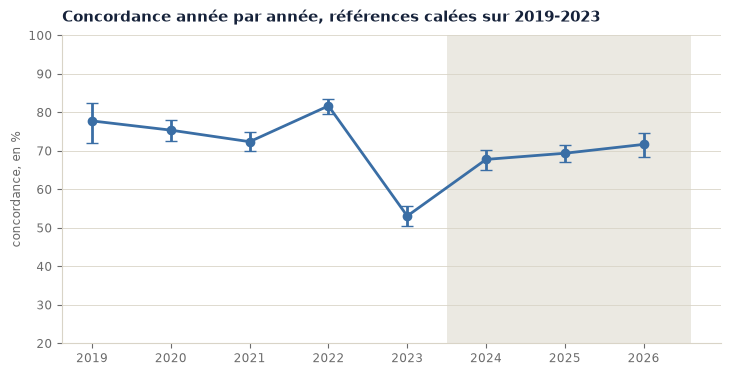

année   concordance   intervalle        étiquetés par le producteur
 2019        77.8 %   [ 72.1 ;  82.5]     1.35 %
 2020        75.4 %   [ 72.5 ;  78.1]      2.3 %
 2021        72.4 %   [ 69.9 ;  74.9]     2.84 %
 2022        81.7 %   [ 79.7 ;  83.5]     3.35 %
 2023        53.1 %   [ 50.5 ;  55.6]     2.71 %
 2024        67.8 %   [ 65.1 ;  70.3]     2.46 %
 2025        69.4 %   [ 67.0 ;  71.6]     2.52 %
 2026        71.7 %   [ 68.5 ;  74.6]     3.03 %


In [9]:
annees = lire("stabilite-par-annee")

figure, axes = plt.subplots(figsize=(8.5, 4))
positions = range(len(annees))
valeurs = [float(ligne["precision_pourcent"]) for ligne in annees]
bas = [v - float(ligne["precision_bas"]) for v, ligne in zip(valeurs, annees, strict=True)]
haut = [float(ligne["precision_haut"]) - v for v, ligne in zip(valeurs, annees, strict=True)]
premiere_de_test = next(i for i, ligne in enumerate(annees) if ligne["periode"] == "test")

axes.axvspan(premiere_de_test - 0.5, len(annees) - 0.4, color=FILET, alpha=0.5, linewidth=0)
axes.errorbar(
    list(positions), valeurs, yerr=[bas, haut], color=SERIE_1, marker="o", capsize=4, linewidth=2
)
axes.set_xticks(list(positions))
axes.set_xticklabels([ligne["annee"] for ligne in annees])
axes.set_ylim(20, 100)
axes.set_ylabel("concordance, en %", color=GRIS, fontsize=8.5)
soigner(axes, "Concordance année par année, références calées sur 2019-2023")
plt.show()

print("année   concordance   intervalle        étiquetés par le producteur")
for ligne in annees:
    intervalle = f"[{ligne['precision_bas']:>5} ; {ligne['precision_haut']:>5}]"
    print(
        f"{ligne['annee']:>5}   {ligne['precision_pourcent']:>9} %   {intervalle:>14}   "
        f"{ligne['part_etiquetee_pourcent']:>6} %"
    )

Pas de dégradation. Les trois années postérieures au calage sont même en légère hausse.

Mais l'année 2023 décroche de près de trente points, et les intervalles interdisent d'y voir du
hasard : celui de 2023 et celui de 2022 sont séparés de plus de vingt points.

**La cause n'est pas établie.** Deux explications se présentent, et les données disponibles ne les
départagent pas :

- la pratique d'étiquetage du producteur a changé cette année-là. La part de marchés qu'il signale
  passe de 3,35 % en 2022 à 2,71 % en 2023 ; mais elle tombe à 2,46 % en 2024, où la concordance
  remonte à 67,8 %. L'explication ne suffit donc pas ;
- quelque chose a changé dans les prix ou dans la collecte de 2023, et il faudrait ouvrir les
  lignes pour le voir.

C'est une question ouverte, et elle vaut mieux qu'une explication inventée après coup. Le projet a
déjà payé cinq fois l'erreur d'écrire la conclusion avant de regarder la mesure.

**La variation entre années, vingt-huit points, est sept fois plus grande que l'effet de fuite qu'on
cherchait à mesurer.** Un découpage unique en deux périodes est donc une réponse faible : une
validation glissante, qui recalerait les références chaque année, est la suite logique.

## 7. Les références bougent-elles ?

Si la médiane de prix d'une famille d'achat se déplace entre deux périodes, une règle calée une
fois pour toutes se désaccorde en silence. On regarde le déplacement, famille par famille.

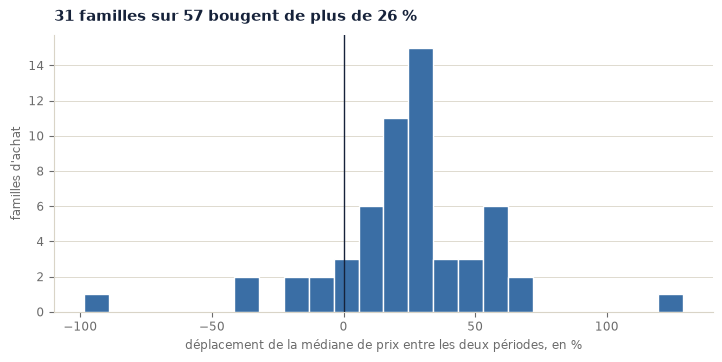

Les cinq familles les plus mobiles :
  CPV 76      -98.6 % de prix   (226 marchés puis 73)
  CPV 33      128.9 % de prix   (37367 marchés puis 33488)
  CPV 64       69.2 % de prix   (5985 marchés puis 4309)
  CPV 93      -40.3 % de prix   (1556 marchés puis 31)
  CPV 60       66.7 % de prix   (23876 marchés puis 14094)


In [10]:
familles = lire("stabilite-familles")
deplacements = [float(ligne["deplacement_prix_pourcent"]) for ligne in familles]
notables = [ligne for ligne in familles if abs(float(ligne["deplacement_log"])) >= 0.1]

figure, axes = plt.subplots(figsize=(8.5, 3.6))
axes.hist(deplacements, bins=24, color=SERIE_1, edgecolor="white")
axes.axvline(0, color=ENCRE, linewidth=1)
axes.set_xlabel(
    "déplacement de la médiane de prix entre les deux périodes, en %", color=GRIS, fontsize=8.5
)
axes.set_ylabel("familles d'achat", color=GRIS, fontsize=8.5)
soigner(axes, f"{len(notables)} familles sur {len(familles)} bougent de plus de 26 %")
plt.show()

print("Les cinq familles les plus mobiles :")
for ligne in familles[:5]:
    print(
        f"  CPV {ligne['famille_cpv']}   {ligne['deplacement_prix_pourcent']:>8} % de prix   "
        f"({ligne['marches_apprentissage']} marchés puis {ligne['marches_test']})"
    )

Trente et une familles sur cinquante-sept bougent de plus de 26 %. Les plus mobiles sont aussi
celles dont l'effectif s'effondre entre les deux périodes : la famille 93 passe de 1 556 marchés à
31, la famille 76 de 226 à 73. Leur médiane n'est plus estimée sur la même chose.

Conclusion pratique : les références doivent être recalculées périodiquement, et la taille de
famille doit être vérifiée **dans la période jugée**, pas seulement sur l'ensemble de l'historique.
C'est un défaut du modèle de production, et il est noté comme tel.

## 8. Ce qu'on peut dire de chaque chiffre

La table finale ne contient pas un intervalle pour tout. Elle nomme, chiffre par chiffre, d'où vient
l'incertitude. C'est le vrai résultat de cette étape.

In [11]:
for ligne in lire("incertitude-sources"):
    valeur = f"{ligne['valeur_pourcent']} %" if ligne["valeur_pourcent"] else "non chiffré"
    print(f"{ligne['chiffre']}")
    print(
        f"    {valeur:<14} {ligne['nature']} -> incertitude dominante : "
        f"{ligne['incertitude_dominante']}"
    )
    print(f"    {ligne['detail']}")
    print()

part des attributions a une PME
    60.8 %         recensement -> incertitude dominante : non-reponse
    compte sur 1999474 attributions, donc aucun hasard de tirage. 6.8 % des titulaires n'ont pas ete resolus : la part reelle est entre 56.7 et 63.5 %

intentions reconnues par l'assistant
    100.0 %        echantillon -> incertitude dominante : tirage, et surtout provenance des questions
    intervalle de Wilson [91.2 ; 100.0] %. Les 40 questions ont ete ecrites par l'auteur du systeme : l'intervalle couvre le tirage, pas ce biais. Un jeu ecrit par un tiers reste a mesurer

avis du BOAMP rapproches d'un marche
    35.7 %         echantillon -> incertitude dominante : tirage
    300 avis tires, intervalle de Wilson [30.5 ; 41.2] %

justesse du rapprochement
    non chiffré    echantillon stratifie, redresse -> incertitude dominante : tirage, sur 60 paires relues seulement
    bootstrap stratifie, voir incertitude-justesse-rapprochement.csv. Les poids viennent du balayage et sont trait

## 9. Bilan

Ce qui change dans le mémoire :

1. **Chaque pourcentage tiré d'un échantillon porte désormais son intervalle.** Le plus spectaculaire
   est 40 sur 40, qui devient « au moins 91 % ».
2. **La justesse du rapprochement est bien moins précise qu'annoncée** : 85,6 % devient
   [76,7 ; 94,0]. La décision de seuil tient quand même, parce que les intervalles des seuils 0,4 et
   0,5 ne se chevauchent pas.
3. **La concordance de la détection était flattée de 4 points** par un calage sur l'historique
   complet. La mesure honnête, hors échantillon, vaut 69,3 % et non 73,3 %.
4. **La part de PME n'est plus une estimation mais un comptage**, 60,8 % des attributions, et son
   incertitude restante, 6,8 points de non-réponse, ne se corrige par aucune formule.

Ce que cette étape n'a pas réglé, et qui est désormais écrit :

- l'année 2023 décroche sans explication établie ;
- la variation entre années dépasse largement l'effet mesuré, donc un découpage unique est une
  réponse faible : la validation glissante reste à faire ;
- les 40 questions de l'assistant ont été écrites par l'auteur du système. L'intervalle couvre le
  tirage, pas ce biais. Un jeu écrit par un tiers reste la mesure manquante ;
- la pertinence des résultats de recherche n'a toujours aucun chiffre, faute de jugement humain. Et
  un chiffre absent vaut mieux qu'un chiffre inventé.